In [17]:

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import Sequential   
from keras.layers import GlobalAvgPool2D,Conv2D,MaxPool2D,BatchNormalization,Dense,Activation,Dropout,ReLU
import sklearn as sk


In [18]:
import os

file_count = 0
for dirname, _, filenames in os.walk('/kaggle/input'):
    file_count += len(filenames)

print(f"Total files: {file_count}")

for dirname, dirnames, filenames in os.walk('/kaggle/input'):
    print(f"{dirname}: {len(filenames)} files")

Total files: 88884
/kaggle/input: 0 files
/kaggle/input/datasets: 0 files
/kaggle/input/datasets/paramaggarwal: 0 files
/kaggle/input/datasets/paramaggarwal/fashion-product-images-small: 1 files
/kaggle/input/datasets/paramaggarwal/fashion-product-images-small/myntradataset: 1 files
/kaggle/input/datasets/paramaggarwal/fashion-product-images-small/myntradataset/images: 44441 files
/kaggle/input/datasets/paramaggarwal/fashion-product-images-small/images: 44441 files


In [19]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    if filenames:
        print(os.path.join(dirname, filenames[0]))
        break

/kaggle/input/datasets/paramaggarwal/fashion-product-images-small/styles.csv


In [20]:
dataset_path = '/kaggle/input/datasets/paramaggarwal/fashion-product-images-small/myntradataset'
df = pd.read_csv(f'{dataset_path}/styles.csv', on_bad_lines='skip')
print(df.columns.tolist())        # all column names
print(df.nunique())                # unique value count per column


['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']
id                    44424
gender                    5
masterCategory            7
subCategory              45
articleType             143
baseColour               46
season                    4
year                     13
usage                     8
productDisplayName    31121
dtype: int64


In [21]:
print(df['masterCategory'].value_counts())

masterCategory
Apparel           21397
Accessories       11274
Footwear           9219
Personal Care      2403
Free Items          105
Sporting Goods       25
Home                  1
Name: count, dtype: int64


In [22]:
df = df[~df['masterCategory'].isin(['Home', 'Sporting Goods','Free Items'])]
print(df['masterCategory'].value_counts())

masterCategory
Apparel          21397
Accessories      11274
Footwear          9219
Personal Care     2403
Name: count, dtype: int64


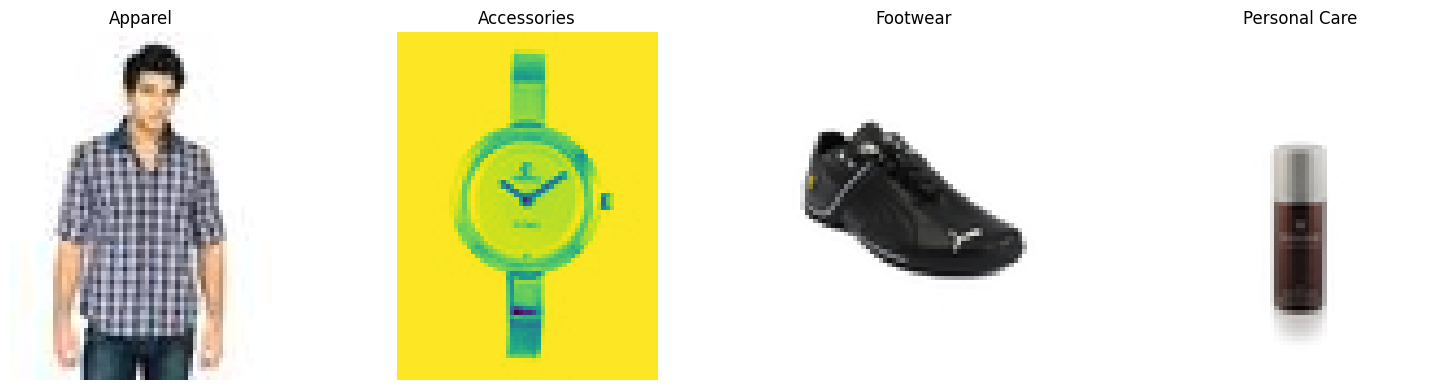

In [23]:
from PIL import Image
from pathlib import Path
dataset_path = Path(dataset_path)

# visualize classes
classes = df['masterCategory'].unique()
fig, axes = plt.subplots(1, len(classes), figsize=(4*len(classes), 4))

for ax, cls in zip(axes, classes):
    sample_id = df[df['masterCategory'] == cls]['id'].iloc[0]
    img_path = dataset_path / 'images' / f'{sample_id}.jpg'
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(cls)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [24]:
from sklearn.model_selection import train_test_split

# split train/val/test
train_df, temp_df = train_test_split(
    df,
    test_size=0.3,
    stratify=df['masterCategory'],
    random_state=42
)
val_df, test_df = train_test_split(
    temp_df,
    test_size= 0.5,
    stratify=temp_df['masterCategory'],
    random_state= 42
)

In [25]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    zoom_range=0.2,
    brightness_range=[0.8, 1.2],
    horizontal_flip=True
)

# normalization
val_datagen = ImageDataGenerator(rescale=1./255) 
test_datagen = ImageDataGenerator(rescale=1./255)

In [26]:
train_df['img_path'] = train_df['id'].astype(str) + '.jpg'
val_df['img_path'] = val_df['id'].astype(str) + '.jpg'
test_df['img_path'] = test_df['id'].astype(str) + '.jpg'

# load images from disk per dataframe row
train_gen = train_datagen.flow_from_dataframe(
    dataframe= train_df,
    directory= dataset_path/'images',
    x_col= 'img_path',
    y_col= 'masterCategory',
    target_size= (80, 60),
    batch_size= 32,
    class_mode='categorical',
    shuffle= True
)

val_gen = val_datagen.flow_from_dataframe(
    dataframe= val_df,
    directory= dataset_path/'images',
    x_col= 'img_path',
    y_col= 'masterCategory',
    target_size= (80, 60),
    batch_size= 32,
    class_mode= 'categorical',
    shuffle= False
)

test_gen = test_datagen.flow_from_dataframe(
    dataframe= test_df,
    directory= dataset_path/'images',
    x_col= 'img_path',
    y_col= 'masterCategory',
    target_size= (80, 60),
    batch_size= 32,
    class_mode='categorical',
    shuffle= False  
)

Found 31001 validated image filenames belonging to 4 classes.
Found 6643 validated image filenames belonging to 4 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/legacy/preprocessing/image.py:918: UserWarning: Found 4 invalid image filename(s) in x_col="img_path". These filename(s) will be ignored.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/legacy/preprocessing/image.py:918: UserWarning: Found 1 invalid image filename(s) in x_col="img_path". These filename(s) will be ignored.
  warnings.warn(


Found 6644 validated image filenames belonging to 4 classes.


In [32]:
from keras.layers import Layer
from keras import Model

class CNNBlock(Layer):
    def __init__(self, filters, kernel_size, padding='same', strides=1):
        super().__init__()
        self.conv = Conv2D(filters, kernel_size, padding=padding, strides=strides)
        self.norm = BatchNormalization()
        self.relu = ReLU()
        self.max_pool = MaxPool2D(pool_size=(2, 2))
        self.dropout = Dropout(0.2)

    
    def call(self, x, training=False):
        x = self.conv(x)
        x = self.norm(x, training=training)
        x = self.relu(x)
        x = self.max_pool(x)
        x = self.dropout(x, training=training)
        return x


class FashionModel(Model):
    def __init__(self, num_classes):
        super().__init__()
        # conv blocks
        self.conv1 = CNNBlock(32, 3)
        self.conv2 = CNNBlock(64, 3)
        self.conv3 = CNNBlock(128, 3)
        
        # collapses each feature map to a single average value per channel
        self.global_avg_pool = GlobalAvgPool2D()
        
        # dense classifier head
        self.dense1 = Dense(512, activation='relu')
        self.dropout1 = Dropout(0.3)
        self.dense2 = Dense(256, activation='relu')
        self.dropout2 = Dropout(0.3)
        
        # output layer
        self.dense3 = Dense(num_classes, activation='softmax')

    def call(self, x, training=False):
        # pass training flag through every block
        # behave correctly depending on train vs inference mode
        x = self.conv1(x, training=training)
        x = self.conv2(x, training=training)
        x = self.conv3(x, training=training)
        x = self.global_avg_pool(x)
        x = self.dense1(x)
        x = self.dropout1(x, training=training)
        x = self.dense2(x)
        x = self.dropout2(x, training=training)
        x = self.dense3(x)
        return x


model = FashionModel(num_classes=4)
model.summary()

Model: "fashion_model_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cnn_block_6 (CNNBlock)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_block_7 (CNNBlock)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_block_8 (CNNBlock)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [34]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer= Adam(learning_rate=5e-4),
    loss= 'categorical_crossentropy', 
    metrics= ['accuracy']
)

In [35]:
from sklearn.utils.class_weight import compute_class_weight

class_labels = list(train_gen.class_indices.keys())     # class names in order used by generator
class_indices = list(train_gen.class_indices.values())  # matching integer indices

weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array(class_labels),
    y=train_df['masterCategory']
)
# take sqrt of weights assigned
weights = np.sqrt(weights)

class_weight_dict = dict(zip(class_indices, weights))
print(class_weight_dict)

{0: np.float64(0.9910426247313812), 1: np.float64(0.7193809930901626), 2: np.float64(1.095986083451131), 3: np.float64(2.146707514080738)}


In [36]:
callbacks= [
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        mode='min',
        patience=5,
        verbose=1
    )

]

In [37]:
history =model.fit(
    train_gen,
    validation_data=val_gen, 
    epochs=35,
    verbose=1,
    class_weight=class_weight_dict,
    callbacks=callbacks
)

Epoch 1/35
969/969 ━━━━━━━━━━━━━━━━━━━━ 211s 209ms/step - accuracy: 0.7619 - loss: 0.6107 - val_accuracy: 0.4957 - val_loss: 2.4900 - learning_rate: 5.0000e-04
Epoch 2/35
969/969 ━━━━━━━━━━━━━━━━━━━━ 107s 111ms/step - accuracy: 0.8427 - loss: 0.4221 - val_accuracy: 0.8195 - val_loss: 0.5280 - learning_rate: 5.0000e-04
Epoch 3/35
969/969 ━━━━━━━━━━━━━━━━━━━━ 89s 91ms/step - accuracy: 0.8651 - loss: 0.3673 - val_accuracy: 0.8737 - val_loss: 0.3250 - learning_rate: 5.0000e-04
Epoch 4/35
969/969 ━━━━━━━━━━━━━━━━━━━━ 87s 90ms/step - accuracy: 0.8886 - loss: 0.3154 - val_accuracy: 0.7960 - val_loss: 0.6294 - learning_rate: 5.0000e-04
Epoch 5/35
969/969 ━━━━━━━━━━━━━━━━━━━━ 87s 90ms/step - accuracy: 0.8992 - loss: 0.2874 - val_accuracy: 0.8282 - val_loss: 0.4176 - learning_rate: 5.0000e-04
Epoch 6/35
969/969 ━━━━━━━━━━━━━━━━━━━━ 87s 89ms/step - accuracy: 0.9105 - loss: 0.2625 - val_accuracy: 0.9112 - val_loss: 0.2548 - learning_rate: 5.0000e-04
Epoch 7/35
969/969 ━━━━━━━━━━━━━━━━━━━━ 89s 91ms

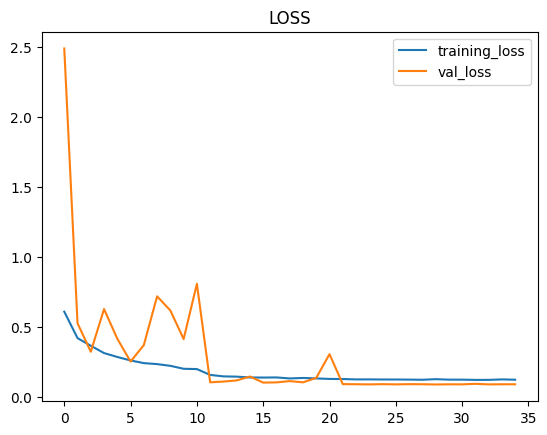

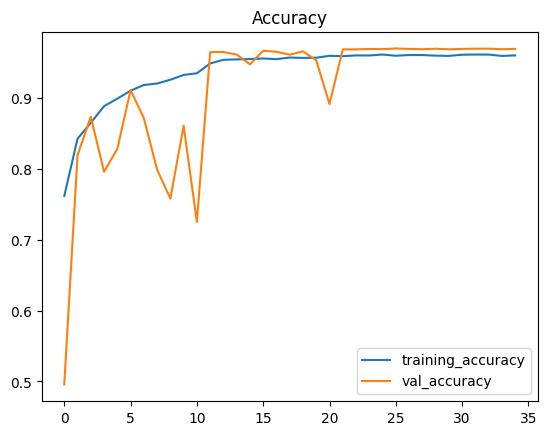

In [38]:
loss = history.history['loss']
val_loss= history.history['val_loss']
plt.plot(loss, label='training_loss')
plt.plot(val_loss, label='val_loss')
plt.legend()
plt.title('LOSS')
plt.show()

accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
plt.plot(accuracy, label='training_accuracy')
plt.plot(val_accuracy, label='val_accuracy')
plt.legend()
plt.title('Accuracy')
plt.show()


In [39]:
y_pred_probs = model.predict(test_gen)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = test_gen.classes

208/208 ━━━━━━━━━━━━━━━━━━━━ 38s 181ms/step


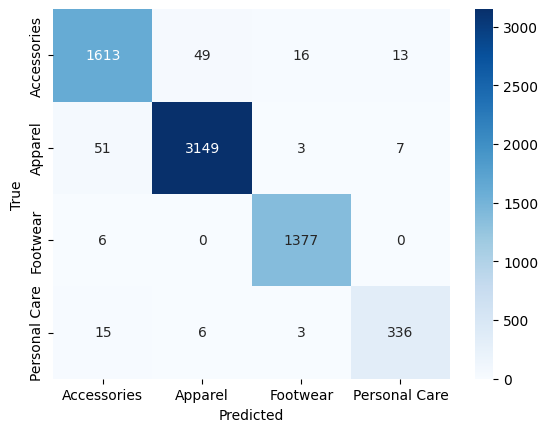

In [40]:
import sklearn
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score

class_names = list(test_gen.class_indices.keys())
cm = sklearn.metrics.confusion_matrix(y_true, y_pred) 
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, 
yticklabels = class_names, 
cmap='Blues') 
plt.xlabel('Predicted') 
plt.ylabel('True') 
plt.show()

In [41]:
print(sklearn.metrics.classification_report(y_true, y_pred, 
target_names=class_names))

               precision    recall  f1-score   support

  Accessories       0.96      0.95      0.96      1691
      Apparel       0.98      0.98      0.98      3210
     Footwear       0.98      1.00      0.99      1383
Personal Care       0.94      0.93      0.94       360

     accuracy                           0.97      6644
    macro avg       0.97      0.97      0.97      6644
 weighted avg       0.97      0.97      0.97      6644



In [44]:
# test accuracy
test_acc = accuracy_score(y_true, y_pred)
print("Test Accuracy:", test_acc)

# test AUC
test_auc = roc_auc_score(y_true, y_pred_probs, multi_class='ovr')
print("Test AUC:", test_auc)

Test Accuracy: 0.9745635159542444
Test AUC: 0.9972596673102327
